<a href="https://colab.research.google.com/github/sitiekbal/CapstnPro_Econ.Analysis/blob/main/Capstone_Project_Economic_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [6]:
import pandas as pd

url = 'https://raw.githubusercontent.com/sitiekbal/CapstnPro_Econ.Analysis/refs/heads/main/Global%20Economic%20Data.csv'
df = pd.read_csv(url)
df.head()

,Country,Year,GDP (in Trillions USD),GDP per Capita (in USD),Inflation Rate (%),Population (in Millions),Population Growth Rate (%),Urban Population (%),Life Expectancy (Years),Healthcare Expenditure per Capita (USD),...,Poverty Rate (%),Number of International Visitors (in Millions),Tourism Revenue (in Billion USD),Agricultural Land (%),Unemployment Rate (%),Labor Force Participation Rate (%),"Crime Rate (per 100,000)",Corruption Perception Index,Freedom of Press Index,Voting Participation Rate (%)
0,USA,2000,20.87,65455.0,2.28,330.34,0.58,83.42,78.39,11209.00,...,10.98,80.80,210.98,42.37,3.55,65.52,287.40,67.41,45.27,68.81
1,Russia,2000,1.64,10923.0,3.25,141.81,0.10,72.67,69.91,534.45,...,12.89,24.70,36.47,12.53,4.63,57.54,497.50,30.90,146.10,65.00
2,Canada,2000,1.65,47932.0,1.96,36.63,0.90,79.54,84.60,5113.50,...,9.46,22.33,29.52,7.22,5.43,65.06,795.20,74.74,16.42,63.00
3,China,2000,13.64,10060.0,2.43,1446.93,0.31,58.56,76.09,459.00,...,2.04,62.20,115.80,54.00,3.68,63.13,102.90,41.75,185.32,72.14
4,India,2000,2.98,2102.1,4.87,1313.76,1.04,34.09,68.78,76.07,...,22.25,11.25,29.12,57.60,7.31,52.10,245.25,40.12,136.36,67.65


In [18]:
# EDA script for "https://raw.githubusercontent.com/sitiekbal/CapstnPro_Econ.Analysis/refs/heads/main/Global%20Economic%20Data.csv"
# Outputs:
# - outputs/missing_summary.csv, outputs/missingness_heatmap.png
# - outputs/summary_stats_by_country.csv, outputs/summary_stats_global.csv
# - outputs/corr_matrix_global.csv, outputs/corr_matrix_global.png
# - outputs/trend_<var>.png (time-series plots)
# - outputs/outliers_impossible.csv, outputs/outliers_zscore.csv
# - outputs/pca_biplot.png, outputs/clusters.csv, outputs/cluster_summary.csv
#
# Requirements:
# pip install pandas numpy matplotlib seaborn scikit-learn scipy seaborn

import os
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from scipy import stats

sns.set(style="whitegrid", context="talk")

# Configuration
INPUT_CSV = "https://raw.githubusercontent.com/sitiekbal/CapstnPro_Econ.Analysis/refs/heads/main/Global%20Economic%20Data.csv"  # path to the pasted CSV
OUTDIR = Path("outputs")
OUTDIR.mkdir(exist_ok=True)

# Utility: tidy column names to simpler keys
def tidy_columns(df):
    df = df.copy()
    cols = {}
    for c in df.columns:
        nc = c.strip()
        nc = nc.replace("\n", " ").replace("\r", " ")
        nc = nc.replace("%", "percent").replace("/", "_").replace("(", "").replace(")", "")
        nc = nc.replace(" ", "_")
        nc = nc.replace("__", "_")
        cols[c] = nc
    df = df.rename(columns=cols)
    return df

# Prepare data from memory
def prepare_data(df):
    df = df.copy()
    df = tidy_columns(df)
    # Convert numeric-looking columns to numeric where possible
    for col in df.columns:
        if col.lower() in ("country",):
            continue
        # Try to coerce to numeric if it is stored as string
        if df[col].dtype == object:
            df[col] = pd.to_numeric(df[col].astype(str).str.replace(",", "").str.strip(), errors='coerce')
        else:
            df[col] = pd.to_numeric(df[col], errors='coerce')
    # Recover Country as string if read as NaN-numeric
    if 'Country' not in df.columns and 'country' in df.columns:
        df.rename(columns={'country': 'Country'}, inplace=True)
    # Year as integer if available
    if 'Year' in df.columns:
        df['Year'] = pd.to_numeric(df['Year'], errors='coerce').astype('Int64')
    return df

# 1) Missingness summary
def missingness_summary(df):
    missing_counts = df.isna().sum().sort_values(ascending=False)
    missing_pct = (missing_counts / len(df) * 100).round(2)
    summary = pd.concat([missing_counts, missing_pct], axis=1)
    summary.columns = ['missing_count', 'missing_pct']
    summary.to_csv(OUTDIR / "missing_summary.csv")
    # heatmap
    plt.figure(figsize=(14, 6))
    sns.heatmap(df.isna().T, cbar=False, cmap="Greys", yticklabels=True)
    plt.title("Missingness heatmap (columns x rows)")
    plt.xlabel("Row index")
    plt.ylabel("Columns")
    plt.tight_layout()
    plt.savefig(OUTDIR / "missingness_heatmap.png", dpi=150)
    plt.close()
    return summary

# 2) Descriptive statistics by country
def descriptive_by_country(df):
    numeric = df.select_dtypes(include=[np.number]).columns.tolist()
    grp = df.groupby('Country')[numeric]
    summary_by_country = grp.agg(['count','mean','median','std','min','max']).round(3)
    # flatten columns
    summary_by_country.columns = ["_".join(col).strip() for col in summary_by_country.columns.values]
    summary_by_country.to_csv(OUTDIR / "summary_stats_by_country.csv")
    # global
    summary_global = df[numeric].agg(['count','mean','median','std','min','max']).round(3).T
    summary_global.to_csv(OUTDIR / "summary_stats_global.csv")
    return summary_by_country, summary_global

# 3) Correlation matrix (pooled)
def correlation_matrix(df):
    numeric = df.select_dtypes(include=[np.number]).columns.tolist()
    corr = df[numeric].corr(method='pearson')
    corr.to_csv(OUTDIR / "corr_matrix_global.csv")
    plt.figure(figsize=(14,12))
    sns.heatmap(corr, cmap="vlag", center=0, xticklabels=True, yticklabels=True)
    plt.title("Pearson correlation matrix (pooled)")
    plt.tight_layout()
    plt.savefig(OUTDIR / "corr_matrix_global.png", dpi=150)
    plt.close()
    return corr

# 4) Time-series plot set
def timeseries_plots(df, vars_to_plot=None):
    if vars_to_plot is None:
        # choose a set of key variables likely present (use tidy names)
        vars_to_plot = [
            'GDP_in_Trillions_USD','GDP_per_Capita_in_USD',
            'CO2_Emissions_Million_Metric_Tons','Renewable_Energy_Share_percent',
            'Human_Development_Index_HDI','Life_Expectancy_Years'
        ]
    # check available
    avail = [v for v in vars_to_plot if v in df.columns]
    countries = df['Country'].dropna().unique()
    for var in avail:
        plt.figure(figsize=(10,6))
        for c in countries:
            sub = df[df['Country']==c].sort_values('Year')
            if var in sub.columns:
                plt.plot(sub['Year'], sub[var], marker='o', label=c)
        plt.title(f"{var} by Country (2000-2023)")
        plt.xlabel("Year")
        plt.ylabel(var)
        plt.legend()
        plt.grid(True, alpha=0.3)
        plt.tight_layout()
        safe_fn = f"trend_{var}.png"
        plt.savefig(OUTDIR / safe_fn, dpi=150)
        plt.close()

    # small multiples (facets) for GDP_per_Capita if available
    if 'GDP_per_Capita_in_USD' in df.columns:
        g = sns.FacetGrid(df, col="Country", col_wrap=3, height=3.5, sharey=False)
        g.map_dataframe(sns.lineplot, x="Year", y="GDP_per_Capita_in_USD", marker="o")
        g.set_axis_labels("Year", "GDP per Capita (USD)")
        plt.tight_layout()
        plt.savefig(OUTDIR / "facet_GDP_per_Capita.png", dpi=150)
        plt.close()

# 5) Outlier checks
def outlier_checks(df):
    outlier_rows = []
    # Example impossible-value checks:
    # - Literacy rate > 100
    literacy_cols = [c for c in df.columns if 'Literacy_Rate' in c or 'literacy' in c.lower()]
    for col in literacy_cols:
        bad = df[df[col] > 100][['Country','Year',col]]
        if not bad.empty:
            outlier_rows.append(("impossible_literacy", col, bad))
    # - Negative population or negative GDP etc.
    numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()
    for col in ['Population_in_Millions','GDP_in_Trillions_USD','GDP_per_Capita_in_USD']:
        if col in df.columns:
            neg = df[df[col] < 0][['Country','Year',col]]
            if not neg.empty:
                outlier_rows.append(("negative_values", col, neg))

    # Save impossible-value table
    impossible_table = pd.DataFrame()
    for tag, col, tbl in outlier_rows:
        tmp = tbl.copy()
        tmp['issue'] = tag
        tmp['column'] = col
        impossible_table = pd.concat([impossible_table, tmp], ignore_index=True)
    impossible_table.to_csv(OUTDIR / "outliers_impossible.csv", index=False)

    # Z-score based multivariate outliers for key variables (flag rows with any variable zscore > 3)
    key_vars = ['GDP_per_Capita_in_USD','GDP_in_Trillions_USD','CO2_Emissions_Million_Metric_Tons',
                'Renewable_Energy_Share_percent','Human_Development_Index_HDI']
    key_vars = [v for v in key_vars if v in df.columns]
    z_outliers = pd.DataFrame()
    if key_vars:
        sub = df[['Country','Year'] + key_vars].dropna()
        zscores = np.abs(stats.zscore(sub[key_vars], nan_policy='omit'))
        mask = (zscores > 3).any(axis=1)
        z_outliers = sub[mask]
        z_outliers.to_csv(OUTDIR / "outliers_zscore.csv", index=False)
    return impossible_table, z_outliers

# 6) Country clustering summary based on development profile
def clustering_summary(df, agg_method='mean', k_range=(2,4)):
    # Select features for profiling (try to pick interpretable indicators if present)
    candidate_features = [
        'GDP_per_Capita_in_USD','Human_Development_Index_HDI','Renewable_Energy_Share_percent',
        'CO2_Emissions_Million_Metric_Tons','Internet_Penetration_percent',
        'Healthcare_Expenditure_per_Capita_USD'
    ]
    # fallback: pick top numeric columns if these aren't present
    available = [c for c in candidate_features if c in df.columns]
    if len(available) < 3:
        numeric = df.select_dtypes(include=[np.number]).columns.tolist()
        available = numeric[:6]  # take first six numeric columns
    # Aggregate per country (latest year or mean)
    if agg_method == 'latest' and 'Year' in df.columns:
        latest = df.loc[df.groupby('Country')['Year'].idxmax()]
        profile = latest[['Country'] + available].set_index('Country')
    else:
        profile = df.groupby('Country')[available].mean()
    profile = profile.dropna(axis=1, how='all').fillna(profile.mean())
    # Standardize
    scaler = StandardScaler()
    X = scaler.fit_transform(profile.values)
    # PCA for 2D visualization
    pca = PCA(n_components=2)
    pcs = pca.fit_transform(X)
    pca_df = pd.DataFrame(pcs, columns=['PC1','PC2'], index=profile.index)
    # Try kmeans for range of k and pick best by silhouette
    best_k = None
    best_score = -1
    best_labels = None
    for k in range(k_range[0], k_range[1]+1):
        km = KMeans(n_clusters=k, random_state=42, n_init=10)
        labels = km.fit_predict(X)
        if len(profile) >= k+1:
            score = silhouette_score(X, labels)
        else:
            score = -1
        if score > best_score:
            best_score = score
            best_k = k
            best_labels = labels.copy()
    # Assign clusters
    profile['cluster'] = best_labels
    profile.to_csv(OUTDIR / "clusters.csv")
    # cluster summary statistics
    cluster_summary = profile.groupby('cluster').agg(['count','mean','std']).round(3)
    cluster_summary.to_csv(OUTDIR / "cluster_summary.csv")
    # Plot PCA scatter
    plt.figure(figsize=(8,6))
    palette = sns.color_palette("tab10", n_colors=len(np.unique(best_labels)))
    for c in profile['cluster'].unique():
        mask = profile['cluster']==c
        plt.scatter(pca_df.loc[mask,'PC1'], pca_df.loc[mask,'PC2'], label=f'cluster {c}', s=100)
        for idx in pca_df[mask].index:
            plt.text(pca_df.loc[idx,'PC1']+0.02, pca_df.loc[idx,'PC2']+0.02, idx, fontsize=9)
    plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f}% var)")
    plt.ylabel(f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f}% var)")
    plt.title("Country clusters (PCA 2D projection)")
    plt.legend()
    plt.tight_layout()
    plt.savefig(OUTDIR / "pca_biplot.png", dpi=150)
    plt.close()
    return profile, cluster_summary, pca_df

def main():
    # Since the df is already in active notebook memory from the previous cell, we can process it directly.
    global df
    if 'df' not in globals():
        raise NameError("DataFrame 'df' not found in memory. Please execute the previous cell first.")

    print("Preparing loaded DataFrame...")
    processed_df = prepare_data(df)
    print(f"Data shape: {processed_df.shape}")

    if 'Country' not in processed_df.columns or 'Year' not in processed_df.columns:
        raise SystemExit("Expected columns 'Country' and 'Year' in the DataFrame. Please check the dataset.")

    # Missingness
    print("Computing missingness summary...")
    miss = missingness_summary(processed_df)
    print(miss.head(10))

    # Descriptive stats
    print("Computing descriptive statistics by country...")
    summary_by_country, summary_global = descriptive_by_country(processed_df)
    print("Saved summary_stats_by_country.csv and summary_stats_global.csv")

    # Correlation matrix
    print("Computing correlation matrix...")
    corr = correlation_matrix(processed_df)
    print("Saved corr_matrix_global.csv and image")

    # Time-series plots
    print("Generating time-series plots...")
    timeseries_plots(processed_df)
    print("Saved trend PNGs")

    # Outlier checks
    print("Running outlier checks...")
    impossible_table, z_outliers = outlier_checks(processed_df)
    if not impossible_table.empty:
        print(f"Found impossible-value outliers; wrote outliers_impossible.csv ({len(impossible_table)} rows)")
    else:
        print("No impossible-value outliers found.")
    if not z_outliers.empty:
        print(f"Found z-score outliers; wrote outliers_zscore.csv ({len(z_outliers)} rows)")
    else:
        print("No z-score outliers found.")

    # Clustering summary
    print("Running country clustering...")
    profile, cluster_summary, pca_df = clustering_summary(processed_df, agg_method='mean', k_range=(2,4))
    print("Saved clusters.csv and cluster_summary.csv and pca_biplot.png")
    print("EDA complete. Outputs saved to the 'outputs' directory.")

if __name__ == "__main__":
    main()

Preparing loaded DataFrame...
Data shape: (144, 36)
Computing missingness summary...
                                       missing_count  missing_pct
Country                                            0          0.0
Year                                               0          0.0
GDP_in_Trillions_USD                               0          0.0
GDP_per_Capita_in_USD                              0          0.0
Inflation_Rate_percent                             0          0.0
Population_in_Millions                             0          0.0
Population_Growth_Rate_percent                     0          0.0
Urban_Population_percent                           0          0.0
Life_Expectancy_Years                              0          0.0
Healthcare_Expenditure_per_Capita_USD              0          0.0
Computing descriptive statistics by country...
Saved summary_stats_by_country.csv and summary_stats_global.csv
Computing correlation matrix...
Saved corr_matrix_global.csv and image
Generat

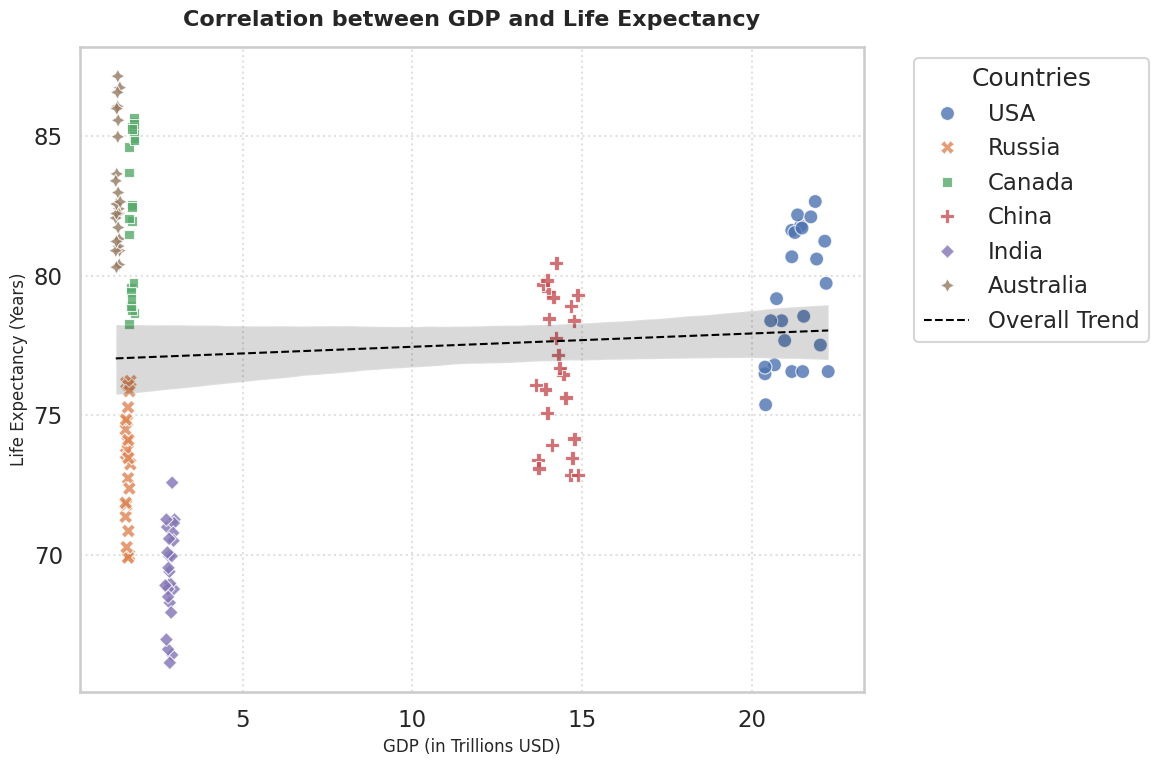

In [19]:
import matplotlib.pyplot as plt
import seaborn as sns

# Prepare the data using the utility from our EDA cell to ensure tidy columns and correct types
cleaned_df = prepare_data(df)

# Create the scatter plot
plt.figure(figsize=(12, 8))
sns.scatterplot(
    data=cleaned_df,
    x='GDP_in_Trillions_USD',
    y='Life_Expectancy_Years',
    hue='Country',
    style='Country',
    s=100,
    alpha=0.8
)

# Add a trendline to show the overall correlation
sns.regplot(
    data=cleaned_df,
    x='GDP_in_Trillions_USD',
    y='Life_Expectancy_Years',
    scatter=False,
    color='black',
    line_kws={'linestyle': '--', 'linewidth': 1.5},
    label='Overall Trend'
)

plt.title('Correlation between GDP and Life Expectancy', fontsize=16, fontweight='bold', pad=15)
plt.xlabel('GDP (in Trillions USD)', fontsize=12)
plt.ylabel('Life Expectancy (Years)', fontsize=12)
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', title='Countries')
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()

# Save the plot
plt.savefig(OUTDIR / 'gdp_vs_life_expectancy_scatter.png', dpi=150)
plt.show()